In [11]:
# Ex 1

import numpy as np
import tensorly as tl
from tensorly.decomposition import parafac, tucker
import time
import matplotlib.pyplot as plt

# Generate a 50x50x50 tensor of CP rank at most 5
rng = np.random.default_rng(42)
n, k = 50, 5

factors = [rng.standard_normal((n, k)) for _ in range(3)]
A = np.einsum("ir,jr,kr->ijk", *factors)

# CP decomposition
cp = parafac(A, rank=k, init="svd")
A_cp = tl.cp_to_tensor(cp)

# Tucker decomposition, multilinear rank (5,5,5)
tk = tucker(A, rank=[k, k, k], init="svd")
A_tucker = tl.tucker_to_tensor(tk)

# Relative reconstruction errors (Frobenius norm)
cp_error = np.linalg.norm((A - A_cp).ravel()) / np.linalg.norm(A.ravel())
tk_error = np.linalg.norm((A - A_tucker).ravel()) / np.linalg.norm(A.ravel())

print("CP relative error:", cp_error)
print("Tucker relative error:", tk_error)


CP relative error: 4.530534776060432e-09
Tucker relative error: 1.3114695828923225e-15


In [12]:

def my_cp(X, r, max_iter=100, tol=1e-8, seed=123):
    n1, n2, n3 = X.shape
    rng = np.random.default_rng(seed)

    A = rng.standard_normal((n1, r))
    B = rng.standard_normal((n2, r))
    C = rng.standard_normal((n3, r))

    def normalize(F):
        weights = np.linalg.norm(F, axis=0)
        safe = np.where(weights > 1e-12, weights, 1.0)
        return F / safe, weights

    A, _ = normalize(A)
    B, _ = normalize(B)
    C, _ = normalize(C)

    previous_error = None

    for _ in range(max_iter):

        # 2. Update A, keeping B and C fixed
        M = np.einsum("ijk,jr,kr->ir", X, B, C)
        G = (B.T @ B) * (C.T @ C)
        A_hat = M @ np.linalg.pinv(G)
        A, weights = normalize(A_hat)

        # 3. Update B, keeping A and C fixed
        M = np.einsum("ijk,ir,kr->jr", X, A, C)
        G = (A.T @ A) * (C.T @ C)
        B_hat = M @ np.linalg.pinv(G)
        B, weights = normalize(B_hat)

        # 4. Update C, keeping A and B fixed
        M = np.einsum("ijk,ir,jr->kr", X, A, B)
        G = (A.T @ A) * (B.T @ B)
        C_hat = M @ np.linalg.pinv(G)
        C, weights = normalize(C_hat)

        X_hat = np.einsum(
            "r,ir,jr,kr->ijk",
            weights, A, B, C
        )

        error = np.linalg.norm(X - X_hat) / np.linalg.norm(X)

        if previous_error is not None:
            if abs(previous_error - error) < tol:
                break

        previous_error = error

    return weights, (A, B, C)


k=5: error=5.599e-12, time=1.237s
k=10: error=3.764e-11, time=0.122s
k=50: error=2.611e-11, time=0.842s


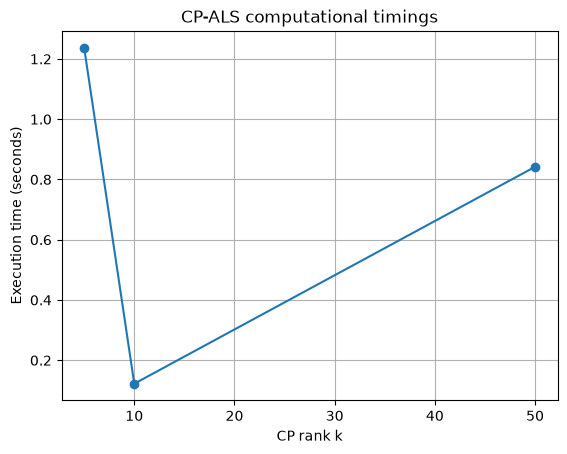

In [13]:
ranks = [5, 10, 50]
times = []
errors = []

for k in ranks:
    rng = np.random.default_rng(42)

    factors = [
        rng.standard_normal((50, k))
        for _ in range(3)
    ]

    X = np.einsum("ir,jr,kr->ijk", *factors)

    start = time.perf_counter()
    weights, (A, B, C) = my_cp(
        X,
        r=k,
        max_iter=500,
        tol=1e-10,
        seed=123
    )
    elapsed = time.perf_counter() - start

    X_hat = np.einsum(
        "r,ir,jr,kr->ijk", weights, A, B, C
    )

    error = np.linalg.norm(X - X_hat) / np.linalg.norm(X)

    times.append(elapsed)
    errors.append(error)

    print(f"k={k}: error={error:.3e}, time={elapsed:.3f}s")

plt.plot(ranks, times, marker="o")
plt.xlabel("CP rank k")
plt.ylabel("Execution time (seconds)")
plt.title("CP-ALS computational timings")
plt.grid(True)
plt.show()


In [14]:



def my_tucker(A, k):
    # Implement Tucker decomposition
    ...